In [1]:
# 第一部分：导入必要的库
# ============================================

import mindspore as ms
from mindspore import nn
import mindspore.dataset as ds
import mindspore.ops as P
from mindspore.nn import SoftmaxCrossEntropyWithLogits
from mindspore.common.initializer import Normal

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from mindquantum.core.circuit import Circuit, UN
from mindquantum.core.gates import H, RY, RZ, CNOT, Rxx, Ryy, Rzz
from mindquantum.core.parameterresolver import PRGenerator
from mindquantum.core.operators import QubitOperator, Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.framework import MQLayer
from mindspore import Tensor
import warnings
warnings.filterwarnings('ignore')

# 尝试导入umap（如果可用）
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("umap-learn 未安装。如需使用UMAP降维，请安装: pip install umap-learn")

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示异常

[WARNING] ME(40932:22880,MainProcess):2026-10-09-15:21:19.560.000 [mindspore\run_check\_check_version.py:543] The directory C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 does not contain the typical file structure of CUDA
[ERROR] ME(40932:22880,MainProcess):2026-10-09-15:21:19.561.000 [mindspore\run_check\_check_version.py:582] CUDA_PATH C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.4 is not safe, skip add cuda path.


In [2]:
# 第二部分：可调参数配置区（电脑A - UMAP实验）
# ============================================

# 数据相关参数
SAMPLE_RATIO = 1            # 数据采样比例
TEST_SIZE = 0.2                # 测试集比例
PCA_COMPONENTS = 8             # 降维目标维度（与量子比特数一致）
BATCH_SIZE = 32                 # 批处理大小

# 降维方法选择（PCA已做，这里只运行UMAP）
DIM_REDUCTION_METHODS = ['umap']   # 将要运行的降维方法列表
RUN_PCA = False                     # 是否重复运行PCA（False表示跳过）

# 量子电路参数
NUM_QUBITS = 8                  # 量子比特数
FIXED_ANSAYZ_TYPE = 'sequential_su4'  # 固定Ansatz类型
FIXED_LAYERS = 2                 # 固定层数

# 训练参数
NUM_EPOCHS = 150                 # 训练轮数
LEARNING_RATE = 0.01             # 学习率
PARALLEL_WORKER = 2              # 并行工作器数量

# MindSpore配置
MS_MODE = ms.PYNATIVE_MODE        # 运行模式
MS_DEVICE = "CPU"                 # 设备目标
SEED = 42                         # 随机种子

# 初始化设置
# ============================================
ms.set_context(mode=MS_MODE, device_target=MS_DEVICE)
ms.set_seed(SEED)
np.random.seed(SEED)

[WARNING] ME(40932:22880,MainProcess):2026-10-09-15:21:26.213.000 [mindspore\context.py:1334] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
# 第三部分：数据加载和处理函数（电脑A - UMAP降维）
# ============================================

import umap
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

def load_mnist_data():
    """加载MNIST数据集（与原始代码相同）"""
    import os
    from torchvision.datasets import MNIST

    print("正在下载/加载MNIST数据集...")
    data_dir = "./MNIST"
    os.makedirs(data_dir, exist_ok=True)

    try:
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)
    except:
        import tempfile
        temp_dir = tempfile.gettempdir()
        data_dir = os.path.join(temp_dir, "MNIST")
        print(f"使用临时目录: {data_dir}")
        train_set = MNIST(data_dir, train=True, download=True)
        test_set = MNIST(data_dir, train=False, download=True)

    def extract_data(dataset):
        images = dataset.data.numpy().astype(np.float32) / 255.0
        labels = dataset.targets.numpy()
        images_flatten = images.reshape(len(images), -1)
        return images_flatten, labels

    train_images, train_labels = extract_data(train_set)
    test_images, test_labels = extract_data(test_set)

    # 合并数据并采样
    all_images = np.concatenate([train_images, test_images])
    all_labels = np.concatenate([train_labels, test_labels])
    sampled_indices = np.random.choice(
        len(all_images),
        int(len(all_images) * SAMPLE_RATIO),
        replace=False
    )
    sampled_images = all_images[sampled_indices]
    sampled_labels = all_labels[sampled_indices]

    print(f"总样本数: {len(all_images)}, 采样后: {len(sampled_images)}")
    print(f"类别分布: {np.unique(sampled_labels, return_counts=True)}")

    return sampled_images, sampled_labels

def preprocess_data_umap(images, labels, umap_model=None, final_scaler=None, is_train=True):
    """
    UMAP降维 + 归一化到[-1,1]预处理函数
    返回: (dataset, final_scaler, umap_model)
    """
    if is_train:
        # 训练集：先缩放到[0,1]用于UMAP
        temp_scaler = MinMaxScaler(feature_range=(0, 1))
        scaled_for_umap = temp_scaler.fit_transform(images)

        # 训练UMAP（参数：n_neighbors=10, min_dist=0.5）
        umap_model = umap.UMAP(n_components=PCA_COMPONENTS, n_neighbors=10, min_dist=0.5, random_state=SEED)
        reduced_data = umap_model.fit_transform(scaled_for_umap)
        print(f"UMAP降维完成，输出形状: {reduced_data.shape}")

        # 将UMAP输出归一化到[-1,1]作为最终特征
        final_scaler = MinMaxScaler(feature_range=(-1, 1))
        normalized_data = final_scaler.fit_transform(reduced_data)

        # 将temp_scaler保存到umap_model中，供测试时使用
        umap_model.temp_scaler = temp_scaler
    else:
        # 测试集：使用训练好的temp_scaler和final_scaler
        temp_scaler = umap_model.temp_scaler
        scaled_for_umap = temp_scaler.transform(images)
        reduced_data = umap_model.transform(scaled_for_umap)
        normalized_data = final_scaler.transform(reduced_data)

    # 创建MindSpore数据集
    dataset = ds.NumpySlicesDataset(
        data=(normalized_data.astype(np.float32), labels.astype(np.int32)),
        column_names=["features", "labels"],
        shuffle=is_train
    ).batch(BATCH_SIZE)

    return dataset, final_scaler, umap_model


In [4]:
# 第四部分：量子电路构建函数（冻结 Ansatz 版本）
# ============================================

def build_encoder():
    """构建编码器电路（固定）"""
    prg = PRGenerator('alpha')
    encoder = Circuit()
    encoder += UN(H, NUM_QUBITS)
    
    for i in range(NUM_QUBITS):
        encoder += RY(prg.new()).on(i)
    
    # 局部 Brickwall 纠缠（一层即可）
    for i in range(0, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    for i in range(1, NUM_QUBITS - 1, 2):
        encoder += CNOT.on(i + 1, i)
    
    encoder = encoder.no_grad()
    encoder.as_encoder()
    return encoder


def build_sequential_su4_ansatz(num_layers):
    """构建顺序SU4 Ansatz（完整结构，参数将被冻结）"""
    theta_prg = PRGenerator('theta')
    ansatz = Circuit()
    
    for layer in range(num_layers):
        # 单比特旋转层
        for qubit in range(NUM_QUBITS):
            ansatz += RY(theta_prg.new()).on(qubit)
            ansatz += RZ(theta_prg.new()).on(qubit)
        
        # 顺序两比特门层
        for i in range(NUM_QUBITS - 1):
            ansatz += Rxx(theta_prg.new()).on([i, i + 1])
            ansatz += Ryy(theta_prg.new()).on([i, i + 1])
            ansatz += Rzz(theta_prg.new()).on([i, i + 1])
            
            ansatz += RY(theta_prg.new()).on(i)
            ansatz += RZ(theta_prg.new()).on(i)
            ansatz += RY(theta_prg.new()).on(i + 1)
            ansatz += RZ(theta_prg.new()).on(i + 1)
    
    # 最终单比特层
    for qubit in range(NUM_QUBITS):
        ansatz += RZ(theta_prg.new()).on(qubit)
        ansatz += RY(theta_prg.new()).on(qubit)
    
    ansatz.as_ansatz()
    return ansatz


def build_ansatz():
    """根据固定参数构建Ansatz"""
    return build_sequential_su4_ansatz(FIXED_LAYERS)


def create_hamiltonians():
    """创建测量哈密顿量 - 仅测量单比特Z"""
    hams = []
    for i in range(NUM_QUBITS):
        hams.append(Hamiltonian(QubitOperator(f'Z{i}', 1.0)))
    return hams

In [5]:
# 第五部分：神经网络定义与训练（冻结Ansatz版本）
# ============================================

class HybridQuantumNet(nn.Cell):
    """混合量子-经典神经网络（仅Z测量，完整Ansatz但冻结）"""
    def __init__(self, quantum_net, num_classes=10):
        super(HybridQuantumNet, self).__init__()
        self.quantum_net = quantum_net
        # 测量维度 = 量子比特数（每个比特一个Z期望值）
        self.fc = nn.Dense(NUM_QUBITS, num_classes, weight_init=Normal(0.02))
        
    def construct(self, x):
        if len(x.shape) == 1:
            x = x.reshape(1, -1)
        elif len(x.shape) > 2:
            x = x.reshape(x.shape[0], -1)
        
        quantum_out = self.quantum_net(x)
        logits = self.fc(quantum_out)
        return logits


def train_model(train_dataset, val_dataset, 
                num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE):
    """
    训练模型（冻结Ansatz：量子电路完整，Ansatz参数随机初始化后不参与训练）
    """
    print(f"\n开始训练: 冻结Ansatz - 结构完整, Ansatz类型={FIXED_ANSAYZ_TYPE}, 层数={FIXED_LAYERS}")
    
    # 构建量子电路（完整结构：encoder + ansatz）
    print("构建量子电路（完整结构）...")
    encoder = build_encoder()
    ansatz = build_ansatz()
    full_circuit = encoder + ansatz
    
    print("量子电路构建完成:")
    print(f"  编码器: {encoder.n_qubits}量子比特")
    print(f"  Ansatz: {ansatz.n_qubits}量子比特，{FIXED_LAYERS}层（参数将随机初始化后冻结）")
    
    # 创建哈密顿量和梯度算子（仅Z测量）
    print("创建哈密顿量和梯度算子...")
    hams = create_hamiltonians()
    print(f"  哈密顿量数量: {len(hams)} (单比特Z)")
    
    sim = Simulator('mqvector', NUM_QUBITS)
    grad_ops = sim.get_expectation_with_grad(
        hams, full_circuit, parallel_worker=PARALLEL_WORKER
    )
    
    # 创建量子层和混合网络
    print("创建神经网络...")
    quantum_net = MQLayer(grad_ops)
    
    # ===== 关键：先把 Ansatz 参数随机初始化为非零值，再冻结 =====
    # 说明：MindQuantum 的 ansatz 参数默认初值为 0，而 RY(0)/RZ(0)/Rxx(0)/Ryy(0)/Rzz(0) 均为恒等门，
    #      因此"默认冻结"在数学上等价于"无 ansatz"。这里先随机初始化为非零值再冻结，
    #      才真正检验"冻结一个非平凡 ansatz"的效果。（p.data 只读，必须用 set_data）
    rng = np.random.RandomState(SEED)      # 固定随机种子，保证结果可复现
    ansatz_param_count = 0
    for p in quantum_net.trainable_params():
        rand_val = rng.uniform(-np.pi, np.pi, size=p.shape).astype(np.float32)
        p.set_data(Tensor(rand_val, dtype=ms.float32))   # 赋随机非零初值
        p.requires_grad = False                           # 冻结：不参与训练
        ansatz_param_count += int(np.prod(p.shape))
    print(f"  已将 Ansatz 参数随机初始化并冻结，参数数量: {ansatz_param_count}")
    
    net = HybridQuantumNet(quantum_net, num_classes=10)
    
    # 打印可训练参数信息（应只剩 fc 层）
    trainable_params = net.trainable_params()
    total_params = sum(int(np.prod(p.shape)) for p in trainable_params)
    print(f"  剩余可训练参数总数: {total_params}（全部来自全连接层）")
    
    # 损失函数和优化器（只更新未冻结的参数）
    loss_fn = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
    optimizer = nn.Adam(trainable_params, learning_rate=learning_rate)
    
    # 定义前向传播和梯度函数
    def forward_fn(data, label):
        if len(data.shape) == 1:
            data = data.reshape(1, -1)
        logits = net(data)
        loss = loss_fn(logits, label)
        return loss, logits
    
    grad_fn = ms.value_and_grad(forward_fn, None, optimizer.parameters, has_aux=True)
    
    # 训练循环
    train_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    
    print(f"\n开始训练循环 ({num_epochs} epochs)...")
    
    for epoch in range(num_epochs):
        # 训练
        net.set_train()
        epoch_loss = 0
        step = 0
        
        for data, label in train_dataset.create_tuple_iterator():
            (loss, _), grads = grad_fn(data, label)
            optimizer(grads)
            epoch_loss += loss.asnumpy()
            step += 1
        
        avg_loss = epoch_loss / step if step > 0 else 0
        train_losses.append(avg_loss)
        
        # 验证
        net.set_train(False)
        correct = 0
        total = 0
        
        for data, label in val_dataset.create_tuple_iterator():
            if len(data.shape) == 1:
                data = data.reshape(1, -1)
            logits = net(data)
            predict = ms.ops.Argmax(output_type=ms.int32)(logits)
            correct += (predict == label).asnumpy().sum()
            total += len(label)
        
        val_acc = correct / total if total > 0 else 0
        val_accuracies.append(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
        
        # 打印进度
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: "
                  f"训练损失={avg_loss:.4f}, 验证准确率={val_acc:.4f}")
    
    print(f"\n训练完成! 最佳验证准确率: {best_val_acc:.4f}")
    
    return train_losses, val_accuracies, best_val_acc


UMAP降维实验 - 冻结Ansatz: sequential_su4, 层数=2

步骤1：加载MNIST数据
正在下载/加载MNIST数据集...
总样本数: 70000, 采样后: 70000
类别分布: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int64), array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958],
      dtype=int64))
数据大小: 70000

步骤2：划分训练集和测试集
训练集: 56000 样本, 测试集: 14000 样本

降维方法: umap

步骤3：UMAP降维预处理
UMAP降维完成，输出形状: (56000, 8)

步骤4：训练量子神经网络（冻结Ansatz）

开始训练: 冻结Ansatz - 结构完整, Ansatz类型=sequential_su4, 层数=2
构建量子电路（完整结构）...
量子电路构建完成:
  编码器: 8量子比特
  Ansatz: 8量子比特，2层（参数将随机初始化后冻结）
创建哈密顿量和梯度算子...
  哈密顿量数量: 8 (单比特Z)
创建神经网络...
  已将 Ansatz 参数随机初始化并冻结，参数数量: 146
  剩余可训练参数总数: 90（全部来自全连接层）

开始训练循环 (150 epochs)...
Epoch   1/150: 训练损失=1.1743, 验证准确率=0.8705
Epoch  10/150: 训练损失=0.2996, 验证准确率=0.9186
Epoch  20/150: 训练损失=0.2801, 验证准确率=0.9234
Epoch  30/150: 训练损失=0.2734, 验证准确率=0.9249
Epoch  40/150: 训练损失=0.2697, 验证准确率=0.9256
Epoch  50/150: 训练损失=0.2673, 验证准确率=0.9265
Epoch  60/150: 训练损失=0.2656, 验证准确率=0.9272
Epoch  70/150: 训练损失=0.2644, 验证准确率=0.9277
Epoch  80/150: 训练损失=0.2634, 验证准确率=0.9280

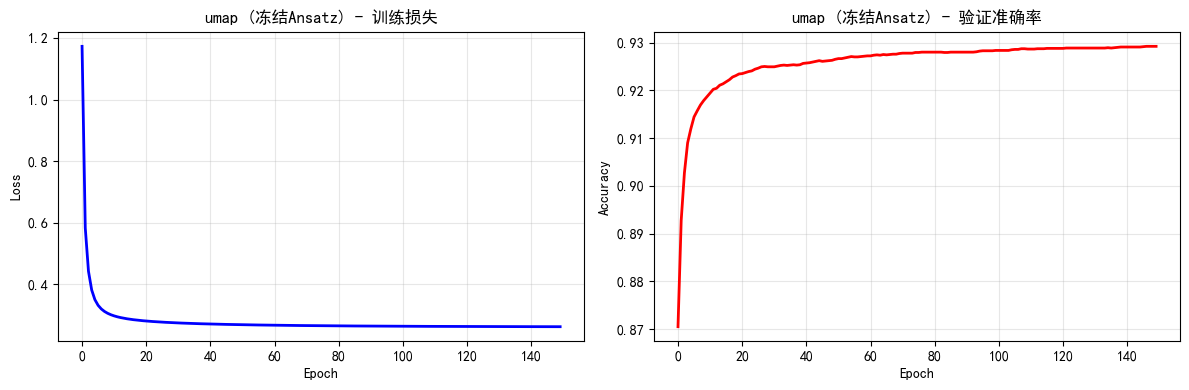


冻结Ansatz实验结果汇总（UMAP）
umap (冻结Ansatz): 最佳验证准确率 = 0.9292

结果已保存到 umap_frozen_randinit_ansatz_nn10_md0.5_results.npz


In [6]:
# 第六部分：主程序 - UMAP降维冻结Ansatz实验
# ============================================

if __name__ == "__main__":
    print("=" * 60)
    print("UMAP降维实验 - 冻结Ansatz: sequential_su4, 层数=2")
    print("=" * 60)

    # 1. 加载数据
    print("\n步骤1：加载MNIST数据")
    all_images, all_labels = load_mnist_data()
    print(f"数据大小: {len(all_images)}")

    # 2. 划分数据集
    print("\n步骤2：划分训练集和测试集")
    train_images, test_images, train_labels, test_labels = train_test_split(
        all_images, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
    )
    print(f"训练集: {len(train_images)} 样本, 测试集: {len(test_images)} 样本")

    # 3. 降维
    all_results = {}

    for method in DIM_REDUCTION_METHODS:
        print(f"\n{'='*60}")
        print(f"降维方法: {method}")
        print(f"{'='*60}")

        if method == 'umap':
            print("\n步骤3：UMAP降维预处理")
            train_dataset, final_scaler, umap_model = preprocess_data_umap(
                train_images, train_labels, is_train=True
            )
            test_dataset, _, _ = preprocess_data_umap(
                test_images, test_labels, umap_model=umap_model, final_scaler=final_scaler, is_train=False
            )
        else:
            raise ValueError(f"未知的降维方法: {method}")

        # 4. 训练模型（冻结 Ansatz）
        print("\n步骤4：训练量子神经网络（冻结Ansatz）")
        train_losses, val_accuracies, best_val_acc = train_model(
            train_dataset=train_dataset,
            val_dataset=test_dataset,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE
        )

        # 存储结果
        all_results[method] = {
            'train_losses': train_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }

        # 5. 绘制曲线
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, 'b-', linewidth=2)
        plt.title(f'{method} (冻结Ansatz) - 训练损失')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, 'r-', linewidth=2)
        plt.title(f'{method} (冻结Ansatz) - 验证准确率')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # 6. 汇总结果
    print("\n" + "=" * 60)
    print("冻结Ansatz实验结果汇总（UMAP）")
    print("=" * 60)
    for method, res in all_results.items():
        print(f"{method} (冻结Ansatz): 最佳验证准确率 = {res['best_val_acc']:.4f}")

    # 7. 保存结果（带参数后缀，便于与不同 UMAP 参数/随机初始化版本对比）
    np.savez('umap_frozen_randinit_ansatz_nn10_md0.5_results.npz',
             train_losses=all_results['umap']['train_losses'],
             val_accuracies=all_results['umap']['val_accuracies'],
             best_val_acc=all_results['umap']['best_val_acc'])
    print("\n结果已保存到 umap_frozen_randinit_ansatz_nn10_md0.5_results.npz")
